In [2]:

import pandas as pd
import numpy as np

df = pd.read_csv("project1_algorithmic_pricing_cleaned.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df[[
    "our_price",
    "competitor_price",
    "units_sold",
    "revenue",
    "marketing_spend",
    "promotion_active"
]].isnull().sum())

print("\nPrice summary:")
print(df["our_price"].describe())

print("\nRegions:")
print(df["region"].value_counts())


Dataset shape: (540, 11)

Columns:
['date', 'region', 'product_category', 'our_price', 'competitor_price', 'units_sold', 'revenue', 'marketing_spend', 'promotion_active', 'treatment', 'period']

Missing values:
our_price           0
competitor_price    0
units_sold          0
revenue             0
marketing_spend     0
promotion_active    0
dtype: int64

Price summary:
count    540.000000
mean     503.778370
std       13.801379
min      482.700000
25%      491.237500
50%      501.370000
75%      510.230000
max      540.100000
Name: our_price, dtype: float64

Regions:
region
North    180
South    180
West     180
Name: count, dtype: int64


In [5]:

%pip install econml scikit-learn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

try:
    import econml
    from econml.dml import LinearDML
    print("EconML version:", econml.__version__)
    print("LinearDML imported successfully")
except Exception as e:
    print("EconML import error:", repr(e))


Scikit-learn version: 1.9.0
EconML version: 0.17.0
LinearDML imported successfully


In [7]:

# Outcome: revenue
Y = df["revenue"].astype(float)

# Treatment: our price (continuous variable)
T = df["our_price"].astype(float)

# Control variables
X = df[
    ["competitor_price", "marketing_spend", "promotion_active"]
].copy()

# Ensure promotion_active is numeric
X["promotion_active"] = X["promotion_active"].astype(int)

print("Y shape:", Y.shape)
print("T shape:", T.shape)
print("X shape:", X.shape)

print("\nMissing values in Y:", Y.isnull().sum())
print("Missing values in T:", T.isnull().sum())
print("Missing values in X:\n", X.isnull().sum())

print("\nTreatment summary:")
print(T.describe())

print("\nControl variable summary:")
print(X.describe())


Y shape: (540,)
T shape: (540,)
X shape: (540, 3)

Missing values in Y: 0
Missing values in T: 0
Missing values in X:
 competitor_price    0
marketing_spend     0
promotion_active    0
dtype: int64

Treatment summary:
count    540.000000
mean     503.778370
std       13.801379
min      482.700000
25%      491.237500
50%      501.370000
75%      510.230000
max      540.100000
Name: our_price, dtype: float64

Control variable summary:
       competitor_price  marketing_spend  promotion_active
count        540.000000       540.000000        540.000000
mean         500.054167       446.973963          0.133333
std           10.899803        82.927186          0.340250
min          472.760000       204.900000          0.000000
25%          492.405000       392.870000          0.000000
50%          500.000000       451.760000          0.000000
75%          507.715000       497.472500          0.000000
max          530.960000       683.140000          1.000000


In [8]:

from econml.dml import LinearDML
from sklearn.ensemble import RandomForestRegressor

# Models for predicting outcome and treatment
model_y = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=10,
    random_state=42
)

model_t = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=10,
    random_state=42
)

# Double Machine Learning model
dml_model = LinearDML(
    model_y=model_y,
    model_t=model_t,
    discrete_treatment=False,
    cv=3,
    random_state=42
)

# Fit the model
dml_model.fit(Y, T, X=X)

print("DML model fitted successfully!")
print("Treatment: our_price")
print("Outcome: revenue")
print("Controls:", X.columns.tolist())


DML model fitted successfully!
Treatment: our_price
Outcome: revenue
Controls: ['competitor_price', 'marketing_spend', 'promotion_active']


In [9]:

# Estimate the effect of our_price on revenue
effect = dml_model.const_marginal_effect(X)

print("Effect output shape:", effect.shape)
print("\nFirst 10 estimated effects:")
print(np.asarray(effect).reshape(-1)[:10])

# Average estimated effect
ate = float(np.asarray(effect).mean())
print("\nAverage estimated price effect:", round(ate, 4))

# Confidence interval for the average treatment effect
ate_interval = dml_model.ate_interval(X=X, T0=0, T1=1)

print("ATE interval:", ate_interval)


Effect output shape: (540,)

First 10 estimated effects:
[209.68754265 197.69321409 149.27548751 127.9618292  168.38577815
 137.36339504 190.88586987 171.80999396 161.27521569 129.4861131 ]

Average estimated price effect: 172.2971
ATE interval: (np.float64(121.68853170735593), np.float64(222.9057167920642))


In [10]:

# Compare a price of 500 with a price of 510
price_before = 500
price_after = 510

# Average estimated effect of a ₹10 price increase
effect_10 = dml_model.ate(
    X=X,
    T0=price_before,
    T1=price_after
)

# 95% confidence interval for this comparison
ci_lower, ci_upper = dml_model.ate_interval(
    X=X,
    T0=price_before,
    T1=price_after
)

print("Price comparison:", price_before, "to", price_after)
print("Estimated revenue effect:", float(effect_10))
print("95% confidence interval:", (float(ci_lower), float(ci_upper)))


Price comparison: 500 to 510
Estimated revenue effect: 1722.9712424971003
95% confidence interval: (1216.8853170738007, 2229.057167920399)


In [11]:

# Save the preliminary DML result summary
dml_results = pd.DataFrame([{
    "outcome": "revenue",
    "treatment": "our_price",
    "control_variables": ", ".join(X.columns),
    "price_before": 500,
    "price_after": 510,
    "price_change": 10,
    "estimated_revenue_effect": float(effect_10),
    "ci_95_lower": float(ci_lower),
    "ci_95_upper": float(ci_upper),
    "interpretation_status": "Preliminary; causal assumptions not yet validated"
}])

dml_results.to_csv("dml_preliminary_results.csv", index=False)

print(dml_results.to_string(index=False))
print("\nSaved: dml_preliminary_results.csv")


outcome treatment                                   control_variables  price_before  price_after  price_change  estimated_revenue_effect  ci_95_lower  ci_95_upper                             interpretation_status
revenue our_price competitor_price, marketing_spend, promotion_active           500          510            10               1722.971242  1216.885317  2229.057168 Preliminary; causal assumptions not yet validated

Saved: dml_preliminary_results.csv


In [12]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predict revenue using the outcome model
y_pred = dml_model.models_y[0][0].predict(X)

rmse = np.sqrt(mean_squared_error(Y, y_pred))
r2 = r2_score(Y, y_pred)

print("Outcome model performance")
print("-------------------------")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Outcome model performance
-------------------------
RMSE: 6440.81
R² Score: 0.4097


C:\Users\rhari\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


In [13]:
# Check how well the treatment model predicts our_price

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

t_model = dml_model.models_t[0][0]

T_pred = t_model.predict(X.to_numpy())

t_rmse = np.sqrt(mean_squared_error(T, T_pred))
t_r2 = r2_score(T, T_pred)

print("Treatment model performance")
print("----------------------------")
print(f"RMSE: {t_rmse:.2f}")
print(f"R² Score: {t_r2:.4f}")

Treatment model performance
----------------------------
RMSE: 11.71
R² Score: 0.2788


In [14]:
print("DOUBLE MACHINE LEARNING — PRELIMINARY RESULTS")
print("-" * 50)

print(f"Outcome model R²: {r2:.4f}")
print(f"Outcome model RMSE: {rmse:.2f}")

print(f"Treatment model R²: {t_r2:.4f}")
print(f"Treatment model RMSE: {t_rmse:.2f}")

print("\nPrice comparison: 500 -> 510")
print(f"Estimated revenue effect: {effect_10:.2f}")
print(f"95% confidence interval: ({ci_lower:.2f}, {ci_upper:.2f})")

print("\nLimitations:")
print("- Results are preliminary and based on synthetic data.")
print("- Predictive performance does not prove causal validity.")
print("- Region, time trends, and demand-related confounding need further investigation.")

DOUBLE MACHINE LEARNING — PRELIMINARY RESULTS
--------------------------------------------------
Outcome model R²: 0.4097
Outcome model RMSE: 6440.81
Treatment model R²: 0.2788
Treatment model RMSE: 11.71

Price comparison: 500 -> 510
Estimated revenue effect: 1722.97
95% confidence interval: (1216.89, 2229.06)

Limitations:
- Results are preliminary and based on synthetic data.
- Predictive performance does not prove causal validity.
- Region, time trends, and demand-related confounding need further investigation.


In [15]:
# Save model diagnostics and preliminary causal estimate

diagnostics = pd.DataFrame([
    {
        "metric": "Outcome model R2",
        "value": r2
    },
    {
        "metric": "Outcome model RMSE",
        "value": rmse
    },
    {
        "metric": "Treatment model R2",
        "value": t_r2
    },
    {
        "metric": "Treatment model RMSE",
        "value": t_rmse
    },
    {
        "metric": "Estimated revenue effect (500 to 510)",
        "value": effect_10
    },
    {
        "metric": "95% CI lower",
        "value": ci_lower
    },
    {
        "metric": "95% CI upper",
        "value": ci_upper
    }
])

diagnostics.to_csv("dml_model_diagnostics.csv", index=False)

print(diagnostics.to_string(index=False))
print("\nSaved: dml_model_diagnostics.csv")

                               metric       value
                     Outcome model R2    0.409692
                   Outcome model RMSE 6440.808126
                   Treatment model R2    0.278790
                 Treatment model RMSE   11.709840
Estimated revenue effect (500 to 510) 1722.971242
                         95% CI lower 1216.885317
                         95% CI upper 2229.057168

Saved: dml_model_diagnostics.csv


In [16]:
# Check the actual intervention and price changes

print("Treatment assignment by region and period:")
print(
    df.groupby(["region", "period"]).agg(
        rows=("treatment", "size"),
        treatment_count=("treatment", "sum"),
        avg_price=("our_price", "mean"),
        avg_revenue=("revenue", "mean"),
        avg_units_sold=("units_sold", "mean")
    ).round(2)
)

print("\nIntervention date:")
print(df.loc[df["treatment"] == 1, "date"].min())

Treatment assignment by region and period:
                       rows  treatment_count  avg_price  avg_revenue  \
region period                                                          
North  post_treatment    60               60     534.58     66366.44   
       pre_treatment    120                0     500.02     61944.39   
South  post_treatment    60                0     489.60     57908.53   
       pre_treatment    120                0     489.95     56217.24   
West   post_treatment    60                0     510.17     69749.19   
       pre_treatment    120                0     509.86     66476.99   

                       avg_units_sold  
region period                          
North  post_treatment          124.15  
       pre_treatment           123.88  
South  post_treatment          118.28  
       pre_treatment           114.73  
West   post_treatment          136.72  
       pre_treatment           130.38  

Intervention date:
2025-05-01


In [17]:
# Compare pre/post revenue changes by region

revenue_comparison = (
    df.groupby(["region", "period"])["revenue"]
      .mean()
      .unstack()
)

revenue_comparison["revenue_change"] = (
    revenue_comparison["post_treatment"]
    - revenue_comparison["pre_treatment"]
)

revenue_comparison["percentage_change"] = (
    revenue_comparison["revenue_change"]
    / revenue_comparison["pre_treatment"] * 100
)

print(revenue_comparison.round(2))

# Simple DiD-style diagnostic
north_change = revenue_comparison.loc["North", "revenue_change"]
south_change = revenue_comparison.loc["South", "revenue_change"]
west_change = revenue_comparison.loc["West", "revenue_change"]

control_change = (south_change + west_change) / 2
did_estimate = north_change - control_change

print("\nNorth revenue change:", round(north_change, 2))
print("Average donor-region change:", round(control_change, 2))
print("Simple DiD-style estimate:", round(did_estimate, 2))

period  post_treatment  pre_treatment  revenue_change  percentage_change
region                                                                  
North         66366.44       61944.39         4422.05               7.14
South         57908.53       56217.24         1691.29               3.01
West          69749.19       66476.99         3272.20               4.92

North revenue change: 4422.05
Average donor-region change: 2481.74
Simple DiD-style estimate: 1940.31


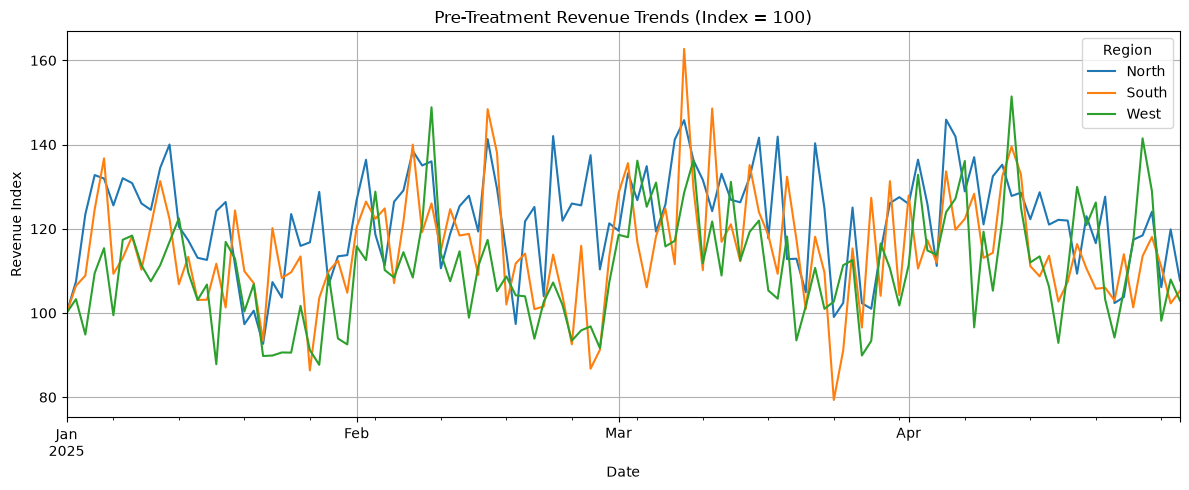

Pre-treatment daily revenue trend (slope per day):
North: 7.35 revenue units/day
South: 2.56 revenue units/day
West: 56.91 revenue units/day


In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Ensure date format is correct
df["date"] = pd.to_datetime(df["date"])

# Keep only pre-intervention observations
pre_df = df[df["date"] < "2025-05-01"].copy()

# Daily revenue by region
daily_revenue = pre_df.pivot(
    index="date",
    columns="region",
    values="revenue"
).sort_index()

# Normalize revenue to the first pre-treatment date
indexed_revenue = daily_revenue.div(
    daily_revenue.iloc[0]
).mul(100)

# Plot pre-treatment trends
indexed_revenue.plot(figsize=(12, 5))

plt.title("Pre-Treatment Revenue Trends (Index = 100)")
plt.xlabel("Date")
plt.ylabel("Revenue Index")
plt.grid(True)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

# Estimate simple linear trend per day
print("Pre-treatment daily revenue trend (slope per day):")

for region in daily_revenue.columns:
    y = daily_revenue[region].to_numpy()
    x = np.arange(len(y))
    slope = np.polyfit(x, y, 1)[0]
    print(f"{region}: {slope:.2f} revenue units/day")

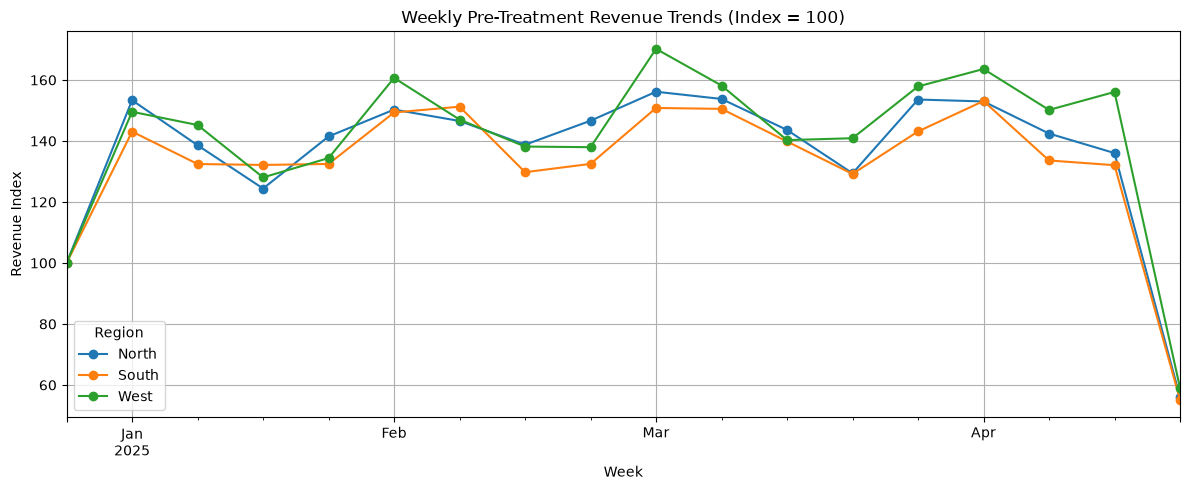

Weekly revenue trend slopes:
North: -1995.05 revenue units/week
South: -2044.52 revenue units/week
West: -35.80 revenue units/week


In [19]:
# Weekly revenue trends before intervention

pre_df = df[df["date"] < "2025-05-01"].copy()

pre_df["week_start"] = (
    pre_df["date"]
    .dt.to_period("W")
    .dt.start_time
)

weekly_revenue = (
    pre_df.groupby(["week_start", "region"])["revenue"]
    .sum()
    .unstack()
    .sort_index()
)

weekly_index = weekly_revenue.div(
    weekly_revenue.iloc[0]
).mul(100)

weekly_index.plot(figsize=(12, 5), marker="o")

plt.title("Weekly Pre-Treatment Revenue Trends (Index = 100)")
plt.xlabel("Week")
plt.ylabel("Revenue Index")
plt.grid(True)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

print("Weekly revenue trend slopes:")

for region in weekly_revenue.columns:
    y = weekly_revenue[region].to_numpy()
    x = np.arange(len(y))
    slope = np.polyfit(x, y, 1)[0]
    print(f"{region}: {slope:.2f} revenue units/week")

In [20]:
print("Weekly data shape:", weekly_revenue.shape)

print("\nFirst 5 weekly totals:")
print(weekly_revenue.head().round(2))

print("\nLast 5 weekly totals:")
print(weekly_revenue.tail().round(2))

print("\nWeekly totals by region:")
print(weekly_revenue.sum().round(2))

Weekly data shape: (18, 3)

First 5 weekly totals:
region          North      South       West
week_start                                 
2024-12-30  301665.46  282202.89  314378.07
2025-01-06  462640.35  403753.49  470245.55
2025-01-13  418070.39  373768.18  456558.55
2025-01-20  375315.65  372906.22  402581.03
2025-01-27  426816.89  373839.27  422498.49

Last 5 weekly totals:
region          North      South       West
week_start                                 
2025-03-31  463333.12  403921.41  496341.09
2025-04-07  461428.61  432050.39  514320.11
2025-04-14  429680.02  377066.23  472143.50
2025-04-21  410384.79  372678.69  490665.22
2025-04-28  169017.43  155869.54  185757.21

Weekly totals by region:
region
North    7433326.99
South    6746069.02
West     7977239.17
dtype: float64


In [21]:
# Count daily observations in each pre-treatment week

days_per_week = (
    pre_df.groupby(
        pre_df["date"].dt.to_period("W").dt.start_time
    )["date"]
    .nunique()
)

print("Number of dates in each week:")
print(days_per_week)

print("\nWeeks with fewer than 7 dates:")
print(days_per_week[days_per_week < 7])

Number of dates in each week:
date
2024-12-30    5
2025-01-06    7
2025-01-13    7
2025-01-20    7
2025-01-27    7
2025-02-03    7
2025-02-10    7
2025-02-17    7
2025-02-24    7
2025-03-03    7
2025-03-10    7
2025-03-17    7
2025-03-24    7
2025-03-31    7
2025-04-07    7
2025-04-14    7
2025-04-21    7
2025-04-28    3
Name: date, dtype: int64

Weeks with fewer than 7 dates:
date
2024-12-30    5
2025-04-28    3
Name: date, dtype: int64


Complete weeks: 16

Full-week trend slopes:
North: 473.25 revenue units/week
South: 244.89 revenue units/week
West: 3164.50 revenue units/week


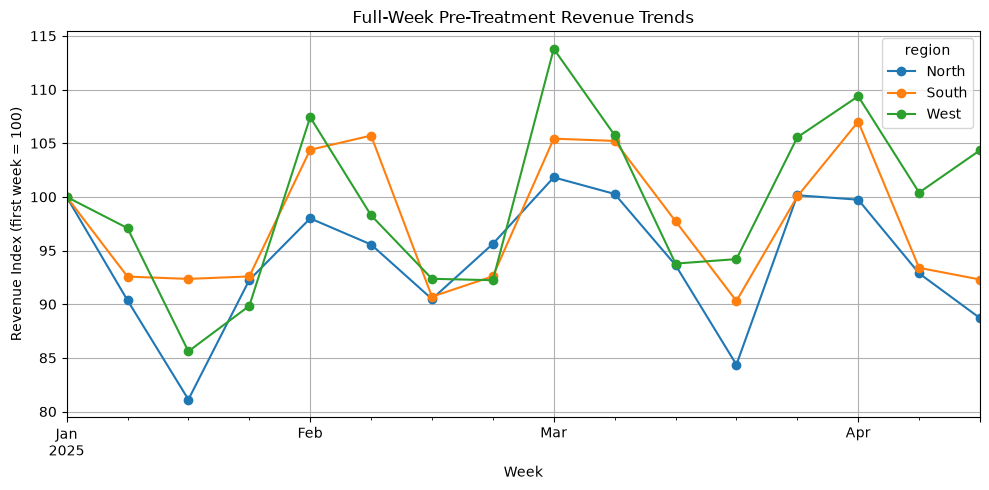

In [22]:
# Keep only complete 7-day pre-treatment weeks

complete_weeks = days_per_week[days_per_week == 7].index

full_week_revenue = weekly_revenue.loc[complete_weeks]

print("Complete weeks:", len(full_week_revenue))

print("\nFull-week trend slopes:")

for region in full_week_revenue.columns:
    y = full_week_revenue[region].to_numpy()
    x = np.arange(len(y))
    slope = np.polyfit(x, y, 1)[0]
    print(f"{region}: {slope:.2f} revenue units/week")

# Plot indexed weekly trends
full_week_index = full_week_revenue.div(
    full_week_revenue.iloc[0]
).mul(100)

full_week_index.plot(figsize=(10, 5), marker="o")
plt.title("Full-Week Pre-Treatment Revenue Trends")
plt.xlabel("Week")
plt.ylabel("Revenue Index (first week = 100)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
from sklearn.ensemble import RandomForestRegressor
from econml.dml import LinearDML
import pandas as pd
import numpy as np

# Create region and time controls
df["date"] = pd.to_datetime(df["date"])

X_adjusted = df[
    ["competitor_price", "marketing_spend", "promotion_active"]
].copy()

X_adjusted["promotion_active"] = X_adjusted["promotion_active"].astype(int)

# Region fixed-effect indicators
region_dummies = pd.get_dummies(
    df["region"], prefix="region", drop_first=True, dtype=int
)

# Linear time trend
X_adjusted["time_trend"] = (
    (df["date"] - df["date"].min()).dt.days
)

X_adjusted = pd.concat(
    [X_adjusted.reset_index(drop=True),
     region_dummies.reset_index(drop=True)],
    axis=1
)

print("Adjusted controls:", X_adjusted.columns.tolist())
print("Adjusted controls shape:", X_adjusted.shape)
print("Missing values:", int(X_adjusted.isna().sum().sum()))

Adjusted controls: ['competitor_price', 'marketing_spend', 'promotion_active', 'time_trend', 'region_South', 'region_West']
Adjusted controls shape: (540, 6)
Missing values: 0


In [24]:
# Fit a separate DML model with region and time controls

model_y_adj = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=10,
    random_state=42
)

model_t_adj = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=10,
    random_state=42
)

dml_adjusted = LinearDML(
    model_y=model_y_adj,
    model_t=model_t_adj,
    discrete_treatment=False,
    cv=3,
    random_state=42
)

dml_adjusted.fit(Y, T, X=X_adjusted)

print("Adjusted DML model fitted successfully!")

Adjusted DML model fitted successfully!


In [25]:
# Compare the same price change using both models

original_effect = dml_model.ate(X=X, T0=500, T1=510)

adjusted_effect = dml_adjusted.ate(
    X=X_adjusted, T0=500, T1=510
)

adj_ci_lower, adj_ci_upper = dml_adjusted.ate_interval(
    X=X_adjusted, T0=500, T1=510
)

print(f"Original DML effect (500 -> 510): {original_effect:.2f}")
print(f"Adjusted DML effect (500 -> 510): {adjusted_effect:.2f}")
print(
    f"Adjusted 95% CI: "
    f"({adj_ci_lower:.2f}, {adj_ci_upper:.2f})"
)

Original DML effect (500 -> 510): 1722.97
Adjusted DML effect (500 -> 510): 3199.03
Adjusted 95% CI: (1077.04, 5321.02)


In [26]:
comparison = pd.DataFrame([
    {
        "model": "Original DML",
        "price_change": 10,
        "estimated_effect": original_effect,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper
    },
    {
        "model": "Adjusted DML",
        "price_change": 10,
        "estimated_effect": adjusted_effect,
        "ci_lower": adj_ci_lower,
        "ci_upper": adj_ci_upper
    }
])

print(comparison.round(2).to_string(index=False))

comparison.to_csv(
    "dml_original_vs_adjusted_comparison.csv",
    index=False
)

print("\nSaved: dml_original_vs_adjusted_comparison.csv")

       model  price_change  estimated_effect  ci_lower  ci_upper
Original DML            10           1722.97   1216.89   2229.06
Adjusted DML            10           3199.03   1077.04   5321.02

Saved: dml_original_vs_adjusted_comparison.csv


## Double Machine Learning (DML) — Findings

### Objective
Estimate the revenue change associated with a price increase from 500 to 510.

### Results

| Model | Estimated Effect | 95% Confidence Interval |
|---|---:|---:|
| Original DML | 1,722.97 | 1,216.89 to 2,229.06 |
| Adjusted DML | 3,199.03 | 1,077.04 to 5,321.02 |

### Interpretation
Adding region and time controls changed the estimated effect and widened the confidence interval. This suggests that the results are sensitive to model specification.

### Limitations
- The dataset is synthetic, not real company data.
- Predictive performance alone does not prove a causal effect.
- Pre-treatment revenue trends differ across regions.
- The continuous price effect is different from the specific intervention effect in North beginning on May 1, 2025.
- Further robustness checks are needed before making a causal claim.

### Conclusion
The preliminary DML models and comparison are complete. The estimated effects are exploratory and should not be treated as confirmed causal results.

In [3]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTreatment Summary:")
print(df["our_price"].describe())

print("\nOutcome Summary:")
print(df["revenue"].describe())

Dataset Shape: (540, 11)

Columns:
['date', 'region', 'product_category', 'our_price', 'competitor_price', 'units_sold', 'revenue', 'marketing_spend', 'promotion_active', 'treatment', 'period']

Missing Values:
date                0
region              0
product_category    0
our_price           0
competitor_price    0
units_sold          0
revenue             0
marketing_spend     0
promotion_active    0
treatment           0
period              0
dtype: int64

Treatment Summary:
count    540.000000
mean     503.778370
std       13.801379
min      482.700000
25%      491.237500
50%      501.370000
75%      510.230000
max      540.100000
Name: our_price, dtype: float64

Outcome Summary:
count      540.000000
mean     62589.045593
std       8390.804369
min      38829.110000
25%      56125.745000
50%      62507.595000
75%      67864.620000
max      91021.500000
Name: revenue, dtype: float64


In [4]:
print("Treatment assignment by region:")
print(pd.crosstab(df["region"], df["treatment"]))

print("\nPeriod distribution:")
print(pd.crosstab(df["region"], df["period"]))

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nData types:")
print(df.dtypes)

Treatment assignment by region:
treatment    0   1
region            
North      120  60
South      180   0
West       180   0

Period distribution:
period  post_treatment  pre_treatment
region                               
North               60            120
South               60            120
West                60            120

Date range:
2025-01-01 to 2025-06-29

Data types:
date                    str
region                  str
product_category        str
our_price           float64
competitor_price    float64
units_sold            int64
revenue             float64
marketing_spend     float64
promotion_active      int64
treatment             int64
period                  str
dtype: object


In [5]:
df["date"] = pd.to_datetime(df["date"])

df["time_trend"] = (
    df["date"] - df["date"].min()
).dt.days

print("Date datatype:", df["date"].dtype)
print("\nTime trend:")
print(df["time_trend"].describe())

Date datatype: datetime64[us]

Time trend:
count    540.000000
mean      89.500000
std       52.008901
min        0.000000
25%       44.750000
50%       89.500000
75%      134.250000
max      179.000000
Name: time_trend, dtype: float64


In [9]:
from econml.dml import LinearDML

In [7]:
print("LinearDML imported successfully!")

LinearDML imported successfully!


In [10]:
# Outcome
Y = df["revenue"].astype(float)

# Treatment
T = df["our_price"].astype(float)

# Confounding/control variables
W = df[
    [
        "competitor_price",
        "marketing_spend",
        "promotion_active"
    ]
].copy()

W["promotion_active"] = W["promotion_active"].astype(int)

print("Y shape:", Y.shape)
print("T shape:", T.shape)
print("W shape:", W.shape)

print("\nMissing values:")
print(W.isnull().sum())

Y shape: (540,)
T shape: (540,)
W shape: (540, 3)

Missing values:
competitor_price    0
marketing_spend     0
promotion_active    0
dtype: int64


In [11]:
# Outcome
Y = df["revenue"].astype(float)

# Treatment
T = df["our_price"].astype(float)

# Confounding/control variables
W = df[
    [
        "competitor_price",
        "marketing_spend",
        "promotion_active"
    ]
].copy()

W["promotion_active"] = W["promotion_active"].astype(int)

print("Y shape:", Y.shape)
print("T shape:", T.shape)
print("W shape:", W.shape)

print("\nMissing values:")
print(W.isnull().sum())

Y shape: (540,)
T shape: (540,)
W shape: (540, 3)

Missing values:
competitor_price    0
marketing_spend     0
promotion_active    0
dtype: int64


In [13]:
region_dummies = pd.get_dummies(
    df["region"],
    prefix="region",
    drop_first=True,
    dtype=int
)

time_control = (df["date"] - df["date"].min()).dt.days

W_adjusted = pd.concat([
    W.reset_index(drop=True),
    region_dummies.reset_index(drop=True),
    time_control.rename("time_trend").reset_index(drop=True)
], axis=1)

print("Adjusted controls:")
print(W_adjusted.columns.tolist())

print("\nShape:", W_adjusted.shape)
print("\nMissing values:", W_adjusted.isnull().sum().sum())

Adjusted controls:
['competitor_price', 'marketing_spend', 'promotion_active', 'region_South', 'region_West', 'time_trend']

Shape: (540, 6)

Missing values: 0


In [14]:
dml_model.fit(
    Y,
    T,
    X=None,
    W=W_adjusted
)

print("Adjusted DML model fitted successfully!")

Adjusted DML model fitted successfully!


In [15]:
# Estimate treatment effect
treatment_effect = dml_model.effect(
    X=None,
    T0=500,
    T1=510
)

print("Estimated treatment effect (500 to 510):", treatment_effect.mean())

# Confidence interval
lower, upper = dml_model.effect_interval(
    X=None,
    T0=500,
    T1=510
)

print("95% Confidence Interval:")
print("Lower:", lower.mean())
print("Upper:", upper.mean())

Estimated treatment effect (500 to 510): 1953.8463832989323
95% Confidence Interval:
Lower: 296.0284255175154
Upper: 3611.664341080349


In [16]:
dml_results = pd.DataFrame({
    "Metric": [
        "Price Change",
        "Estimated Effect",
        "CI Lower",
        "CI Upper"
    ],
    "Value": [
        "500 to 510",
        treatment_effect.mean(),
        lower.mean(),
        upper.mean()
    ]
})

dml_results.to_csv("dml_adjusted_results.csv", index=False)

print("Results saved successfully!")

Results saved successfully!
